## Creating a Logistic Regression Model

### Discovery

You have been tasked with trying to determine if there is a linear relationship between the patients cholesterol levels and other characteristics. You will use a linear regression model to establish if any relationship exists and if so, how cholesterol levels are impacted by other chemicals, substances and health measures. 

First we will import the required modules. They are:
- pandas
- seaborn
- statsmodels.api
- sklearn.model_selection - train_test_split
- sklearn.metrics - confusion_matrix
- matplotlib.pyplot

In [1]:
# Import required modules
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix

--- 
### Data preparation
Import the diabetes dataset and restrict to the required columns.

In [5]:
# Import the first dataset and set the date as the index
df = pd.read_csv("DummyData.csv")
df.head()

,X1 (BMI),X2 (LDL),Y
0,20.1,2.43,0
1,17.7,2.04,0
2,19.7,3.37,0
3,23.1,2.60,0
4,26.5,3.64,1


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   X1 (BMI)  30 non-null     float64
 1   X2 (LDL)  30 non-null     float64
 2   Y         30 non-null     int64  
dtypes: float64(2), int64(1)
memory usage: 852.0 bytes


---
### Building the model
Split the data into training and test datasets - include the random_state argument:<br>
random_state = 25

Set both the independent variable and dependent variable - remember to check they are set correctly. Don't forget to add a constant to your independent variables. 

In [7]:
# Set the dependent variable and validate
dep = df["Y"]
dep.head()

0    0
1    0
2    0
3    0
4    1
Name: Y, dtype: int64

In [8]:
# Set the independent variable and validate
ind = df[["X1 (BMI)", "X2 (LDL)"]]
ind.head()

,X1 (BMI),X2 (LDL)
0,20.1,2.43
1,17.7,2.04
2,19.7,3.37
3,23.1,2.60
4,26.5,3.64


In [9]:
# Remember to add the constant 
ind = sm.add_constant(ind)
ind.head()

,const,X1 (BMI),X2 (LDL)
0,1.0,20.1,2.43
1,1.0,17.7,2.04
2,1.0,19.7,3.37
3,1.0,23.1,2.60
4,1.0,26.5,3.64


Now generate the logistic regression model along with a summary output. 

In [10]:
# Fit the model and produce the summary
model = sm.Logit(dep,ind).fit()
model.summary()

# Model 1 with age and SBP  - PRS 0.2374
# Model 2 without - PRS 0.2344

Optimization terminated successfully.
         Current function value: 0.138734
         Iterations 9


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:                      Y   No. Observations:                   30
Model:                          Logit   Df Residuals:                       27
Method:                           MLE   Df Model:                            2
Date:                Fri, 04 Sep 2026   Pseudo R-squ.:                  0.6467
Time:                        16:26:41   Log-Likelihood:                -4.1620
converged:                       True   LL-Null:                       -11.780
Covariance Type:            nonrobust   LLR p-value:                 0.0004914
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const        -24.0113     11.268     -2.131      0.033     -46.096      -1.927
X1 (BMI)       0.1701      0.220      0.771      0.440      -0.262       0.602
X2 (LDL)       5.8154      3.314      1.755      0.079      -0.680      12.311
==============================================================================
"""

--- 
### Communicating the results. 
You will now analyse the model and communicate the results. What do the following outputs tell you about the model

- Pseudo R-Squared:
- P-Value:
- Coefficient:

In [11]:
# Use the model to predict which dates we are likely to hit high oil prices. Check the output.
predictions = model.predict(ind) >= 0.5
#pred_num = model.predict(ind)
predictions.head()
#pred_num.head()

0    False
1    False
2    False
3    False
4     True
dtype: bool

Once we have our preductions - we can use these to create a confusion matrix, which will help us to assess the model quality. 

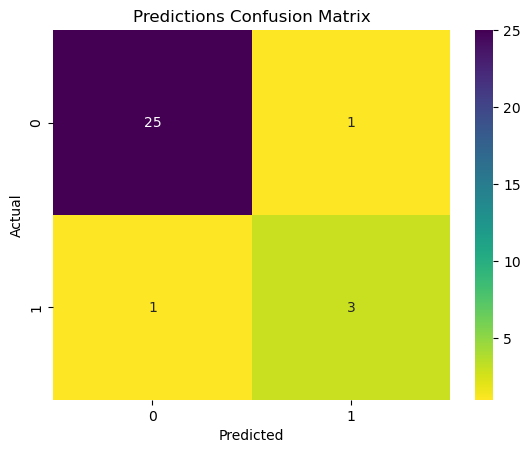

In [12]:
# Generate a confusion matrix to test the model
conf_mat = confusion_matrix(dep, predictions)

# (Optional) Generate the confusion matrix as a heatmap
confusion_mat_heatmap = sns.heatmap(conf_mat, annot = True, cmap = 'viridis_r', fmt='g')

# (Optional) set x and y labels, and create a title
confusion_mat_heatmap.set_xlabel('Predicted')
confusion_mat_heatmap.set_ylabel('Actual')
confusion_mat_heatmap.set_title("Predictions Confusion Matrix")
plt.show()

The model was correct in 2775 cases; 

The model was incorrect in 452 cases. 

Total = 3227 cases

That's a great overall success rate! 
2775/3227 * 100 = 85% accuracy

**Basic Terminology**

**True Positives (TP)** is 65: The model correctly predicted a large purchase. (Bottom right)

**True Negatives (TN)** is 2603: The model correctly predicted that it wont be a large purchase. (Top left)

**False Positives (FP)** is 253: The model incorrectly predicted a large purchase. (Top right)

**False Negatives (FN)** is 306: The model incorrectly predicted it wont be a large purchase. (Bottom left)

In [13]:
# Check incorrectly predicted rows
output = model.predict(ind) >= 0.5
train["predicted"] = output
train = train[["LDL","high_chol","predicted"]]
inc_diff = train[train["high_chol"] != train["predicted"]]
inc_diff.head()
inc_diff["LDL"].median()

NameError: name 'train' is not defined

In [19]:
# Test the model 
dep_test = test["high_chol"]
ind_test = test[["LDL"]]
ind_test = sm.add_constant(ind_test)

# Produce the output and save to a dataframe column - then validate
output = model.predict(ind_test) >= 0.5
num_ouput = model.predict(ind_test)
test["predicted"] = output
test["numeric_predicted"] = num_ouput

# (Optional) Create a dataframe where only incorrect predictions are displayed
test = test[["LDL","high_chol","predicted","numeric_predicted"]]
inc_diff = test[test["high_chol"] != test["predicted"]]
inc_diff

,LDL,high_chol,predicted,numeric_predicted
1096,4.760000,True,False,0.465250
2859,4.110000,True,False,0.258470
4229,4.860753,False,True,0.500639
1297,3.790000,True,False,0.181792
597,3.950000,True,False,0.217704
...,...,...,...,...
3068,4.860753,False,True,0.500639
3863,4.860753,False,True,0.500639
3110,4.860753,False,True,0.500639
1292,4.360000,True,False,0.331341


In [20]:
print(diabetes_df.loc[597])

Age            33
BMI          24.7
Chol         6.43
HDL          1.21
LDL          3.95
SBP           126
high_chol    True
Name: 597, dtype: object


<Axes: xlabel='LDL', ylabel='numeric_predicted'>

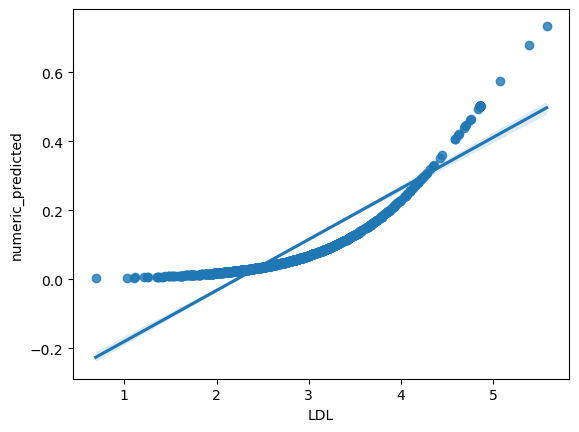

In [21]:
sns.regplot(x = "LDL",
            y = "numeric_predicted",
            data = test)

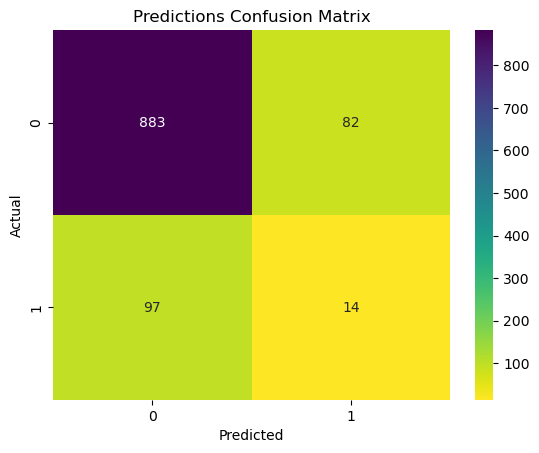

In [22]:
# (Optional) Create a confusion matrix to display test results

tconf_mat = confusion_matrix(dep_test,output)
tconf_mat

# (Optional) Replicate the results as a heatmap as before:
tconfusion_mat_heatmap = sns.heatmap(tconf_mat, annot = True, cmap = 'viridis_r', fmt='g')

# (Optional) set x and y labels, and create a title
tconfusion_mat_heatmap.set_xlabel('Predicted')
tconfusion_mat_heatmap.set_ylabel('Actual')
tconfusion_mat_heatmap.set_title("Predictions Confusion Matrix")
plt.show()

---
### Stretch task
Create a new dataframe with some example data, and generate some predictions using your model.

--- 

In [23]:
# Create a new dataframe

In [24]:
# Generate predictions

In [25]:
# Generate results in the dataframe, based on new dataset

--- 
### Operationalise
In the real world, this is where you would draft a report, deliver briefings, implement with automation on production level servers, produce technical documentation and build this into your BAU process. This being a fictional company, the ever grateful management have granted you paid leave for all your hard work and have volunteered to take on this burden themselves. Congratulations and well done!